[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/05-deep-learning-llms/06_attention.ipynb)

*Deep Learning & LLMs · Notebook 6 of 10*

# Attention & Transformers

The idea behind every modern LLM: scaled dot-product attention by hand, masks, self- and cross-attention, multi-head attention, positional information and the full transformer block.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Attention is a soft lookup: each word asks a question, and all the others answer in proportion to how relevant they are.

**What interviewers really test here:** Writing out attention, why divide by √d, masks, multi-head and complexity.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Attention is a soft dictionary lookup *(Basics)*
- [ ] 2. Scaled dot-product attention, by hand *(Core)*
- [ ] 3. Queries, keys and values are learned *(Core)*
- [ ] 4. Masks: what attention mustn't see *(Core)*
- [ ] 5. Multi-head attention *(Core)*
- [ ] 6. The transformer block *(Core)*
- [ ] 7. Costs, and a transformer in PyTorch *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import numpy as np
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### The formula, piece by piece

| Piece | Shape (one sequence) | Purpose |
| --- | --- | --- |
| Q·Kᵀ | (T\_q, T\_k) | similarity of every pair |
| ÷ √d | same | keeps the spread near 1 |
| mask → −∞ | same | hides positions |
| softmax over keys | same | each row sums to 1 |
| × V | (T\_q, d) | weighted average of values |

### Attention variants

| Type | Q from | K, V from | Used for |
| --- | --- | --- | --- |
| Self-attention | sequence | same sequence | encoders, classifiers |
| Masked self-attention | sequence | same, past only | LLMs, generation |
| Cross-attention | decoder | encoder | translation, image-to-text |

### Design choices in a block

- **Pre-norm** (norm before each sublayer) is common in recent models, and tends to train more stably.
- **Feed-forward width** is about 4d in the classic design.
- **Activation:** ReLU originally; GELU and variants are now common.
- **Positions:** sinusoidal, learned or rotary, depending on the model.
- **Weight tying** shares the token table with the output layer, saving memory.

---
# Part 2: Lessons, step by step

## Lesson 1: Attention is a soft dictionary lookup

*Level: Basics*

A Python dictionary finds an exact key and returns its value. **Attention** is a fuzzy version: compare your query with *every* key, then return a blend of all values, weighted by how well they matched.



**By hand.** Keys 1, 2, 3, values 10, 20, 30, query 2.1. Use similarity = −(query − key)²:



| Key | Value | Similarity | Weight (softmax) |
| --- | --- | --- | --- |
| 1 | 10 | −1.21 | 0.172 |
| 2 | 20 | −0.01 | 0.571 |
| 3 | 30 | −0.81 | 0.257 |



Answer: 0.172·10 + 0.571·20 + 0.257·30 = **20.85**. It's mostly the value of the closest key, nudged towards 30 because the query sits a little on that side. With query 2.0 exactly, the weights are symmetric (0.212, 0.576, 0.212), giving exactly **20**. With query 1 and keys 1, 5, the far key gets a weight near zero, so the answer is about 10: nearly an exact lookup.



Why does it matter that it's soft? A weighted average is **differentiable**, so gradients can flow through the choice of what to look at, and the network learns what to pay attention to.



In language: for each word, the model asks "which other words help me understand this one?" In "The animal didn't cross the street because *it* was tired", "it" should attend to "animal".

**✏️ Your turn:** you now have what you need for [Q3](#q3). Try one now, or carry on and do them in Part 3.

## Lesson 2: Scaled dot-product attention, by hand

*Level: Core*

**Attention(Q, K, V) = softmax(Q·Kᵀ / √d) · V**



Take three tokens with 2-dimensional vectors, using X for Q, K and V alike: (1, 0), (0, 1), (1, 1). Here d = 2, so √d = 1.414.



**Step 1: scores.** Dot every query with every key, and divide by 1.414:



|   | k₁ | k₂ | k₃ |
| --- | --- | --- | --- |
| q₁ | 0.707 | 0 | 0.707 |
| q₂ | 0 | 0.707 | 0.707 |
| q₃ | 0.707 | 0.707 | 1.414 |



**Step 2: softmax each row.** Each row now sums to 1, a budget of attention for that token:



|   | k₁ | k₂ | k₃ |
| --- | --- | --- | --- |
| q₁ | 0.401 | 0.198 | 0.401 |
| q₂ | 0.198 | 0.401 | 0.401 |
| q₃ | 0.248 | 0.248 | 0.503 |



**Step 3: blend the values.** For token 1: 0.401·(1, 0) + 0.198·(0, 1) + 0.401·(1, 1) = **(0.802, 0.599)**.



The result has the same shape as the input, but each token now contains information from others it found relevant. The token count is unchanged, and any length works with the same weights.



**Why divide by √d?** For random vectors with variance 1, a dot product's variance grows in proportion to d. So at large d, scores get large, and softmax turns almost all-or-nothing. Compare softmax of (1, 2, 3) = (0.09, 0.245, 0.665) with softmax of (10, 20, 30), which is about (0, 0, 1). Almost-all-or-nothing means tiny gradients. Dividing by √d brings the spread back to about 1, and the chart shows this.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

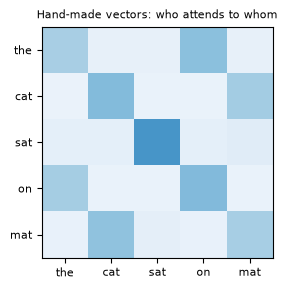

In [2]:
def attention_heatmap():
    tokens = ["the", "cat", "sat", "on", "mat"]
    X = np.array([[0.1, 0.1, 0.9], [1.0, 0.1, 0.1], [0.1, 1.0, 0.1], [0.1, 0.1, 1.0], [0.9, 0.2, 0.1]])
    S = X @ X.T / np.sqrt(3) * 4
    A = np.exp(S) / np.exp(S).sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(3.4, 3))
    ax.imshow(A, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(5), tokens, fontsize=8)
    ax.set_yticks(range(5), tokens, fontsize=8)
    ax.set_title("Hand-made vectors: who attends to whom", fontsize=8)


attention_heatmap()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q10](#q10), [Q7](#q7). Try one now, or carry on and do them in Part 3.

## Lesson 3: Queries, keys and values are learned

*Level: Core*

So far Q, K and V were all X itself. A real layer first passes X through three learned matrices:



**Q = X·W\_q, K = X·W\_k, V = X·W\_v**



| Part | Plain meaning |
| --- | --- |
| Query | what this token is looking for |
| Key | what this token offers to be found by |
| Value | what this token passes on if chosen |



A verb could look for its subject while offering itself to be found by something else entirely. Separate matrices allow that. Without them, a token's query and key are the same vector, so it tends to match itself strongly.



**A small example.** X = (1, 0), (0, 1); W\_q is the identity; W\_k swaps the two axes; W\_v = (2), (3), so V = 2, 3.



- Q = (1, 0), (0, 1). K = (0, 1), (1, 0). So token 1 now matches token *2's* key best.
- Scores for token 1: (0, 0.707). Softmax: 0.3302, 0.6698.
- Output: 0.3302·2 + 0.6698·3 = **2.6698**.



Token 1 now reads mostly from token 2, purely because of learned weights.



**Terminology:** in **self-attention**, Q, K and V all come from one sequence. In **cross-attention**, queries come from one (decoder), keys and values from another (encoder). That's how a translator looks at the source sentence: query (1, 0) against encoder states (1, 0), (0, 1), (1, 1) returns (0.802, 0.599).

**✏️ Your turn:** you now have what you need for [Q13](#q13), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 4: Masks: what attention mustn't see

*Level: Core*

Masks hide positions by setting their scores to −∞ before softmax, since e^(−∞) = 0. Remaining weights still sum to 1.



**By hand:** scores 1, 2, 3 with only the first two allowed: e¹ = 2.718, e² = 7.389, so the weights are 2.718/10.107 = **0.269**, 7.389/10.107 = **0.731** and exactly 0.



Why −∞, instead of multiplying by 0 after softmax? The weights wouldn't sum to 1 any more. And setting scores to 0 before softmax wouldn't work either, because e⁰ = 1 still takes a share.



**Padding mask:** don't attend to padding. **Causal mask:** when predicting token t, don't look at later tokens, because that would be cheating:



```python
[[1, 0, 0],      # token 0 sees itself
 [1, 1, 0],      # token 1 sees tokens 0 and 1
 [1, 1, 1]]      # token 2 sees everything before it
```



Combine them by multiplying. For padding mask (1, 1, 0), the last column goes to zero: [[1,0,0], [1,1,0], [1,1,0]].



**By hand with the earlier vectors:** token 1 = (0, 1) can only see tokens 0 and 1. Scores: 0 and 0.707. Weights: 0.330, 0.670. Output: **(0.330, 0.670)**. Without the mask it got (0.599, 0.802), but that included information from the future.



A language model without a causal mask would score brilliantly in training (the answer is in its input) and fail completely when generating. If your training loss looks too good, this is a good thing to check.

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q11](#q11), [Q12](#q12), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 5: Multi-head attention

*Level: Core*

One attention has one way of relating tokens. A word may need several at once: its grammar, what it refers to, nearby words. **Multi-head attention** runs several smaller attentions side by side.



With d = 4 and 2 heads, each token's vector is split in half:



```python
X = [[1, 2, 3, 4],        head 0: [[1, 2],     head 1: [[3, 4],
     [5, 6, 7, 8]]                 [5, 6]]              [7, 8]]
```



Each head computes attention on its own. Then the pieces are joined back to the original shape, and a final linear layer mixes them.



| Stage | Shape (d = 512, 8 heads, T = 100) |
| --- | --- |
| Input | (100, 512) |
| Split | (8, 100, 64) |
| Attention per head | (8, 100, 64) |
| Concatenate + mix | (100, 512) |



Each head has d/h = 512/8 = **64** dimensions, so 8 heads cost about the same as one large one. Parameters: 4 maps of d × d (Q, K, V, output) = 4 · 512² = **1,048,576**, and this doesn't depend on the number of heads.



**A common mistake:** d must divide evenly by h. Also, don't over-interpret a chart of attention weights: heads rarely map onto neat ideas like "the grammar head", and high attention doesn't necessarily explain a decision.

**✏️ Your turn:** you now have what you need for [Q14](#q14), [Q5](#q5), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 6: The transformer block

*Level: Core*

Stack these four parts, and you've built what's inside an LLM:



```python
x = x + attention(norm(x))      # tokens communicate
x = x + feed_forward(norm(x))   # each token thinks on its own
```



**Feed-forward.** The same small network is applied to each position separately. Attention mixes information *between* tokens; this transforms it *within* one.



For x = (1, 2) with W₁ = identity and b₁ = (0, −1): hidden = ReLU(1, 1) = (1, 1). With W₂ = [[1, 1], [1, −1]] and b₂ = (0.5, 0.5): output = (1 + 1 + 0.5, 1 − 1 + 0.5) = **(2.5, 0.5)**.



**Add and norm.** A residual path (as in ResNet) keeps gradients flowing. Layer norm keeps values stable, with no dependence on batch. x = (1, 2) plus sublayer (1, 0) gives (2, 2): every value is the same, so normalised they're all 0. For (1, 2, 3) with sublayer 0: mean 2, std 0.8165, giving (−1.2247, 0, 1.2247).



**Size of one block** (d = 768):



<table><tr><th>Part</th><th>Formula</th><th>Parameters</th></tr> <tr><td>Attention</td><td>4d²</td><td>2,359,296</td></tr> <tr><td>Feed-forward 1</td><td>4d² + 4d</td><td>2,362,368</td></tr> <tr><td>Feed-forward 2</td><td>4d² + d</td><td>2,360,064</td></tr> <tr><td>Two layer norms</td><td>4d</td><td>3,072</td></tr> <tr><td colspan="2"><b>Total</b></td><td><b>7,084,800</b></td></tr></table>



A 12-block model holds 85 million. Add a 50,000 × 768 token table and 1,000 × 768 positions, and you have about **124 million**. If the output layer shares the token table (**weight tying**), it avoids another 38.4 million parameters, or 153.6 MB.

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q18](#q18), [Q16](#q16), [Q6](#q6), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 7: Costs, and a transformer in PyTorch

*Level: Advanced*

**Attention compares every token with every token**, so cost grows with the square of length:



| Tokens T | T² | Relative to 100 tokens |
| --- | --- | --- |
| 100 | 10,000 | 1× |
| 1,000 | 1,000,000 | 100× |
| 4,000 | 16,000,000 | 1,600× |



This matters for real applications, because longer prompts are slower and need more memory. Generation uses tricks to reduce the cost, such as caching earlier keys and values, which the next topic explains.



```python
import torch, torch.nn as nn, torch.nn.functional as F

class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x, mask):
        y = self.norm1(x)
        x = x + self.attn(y, y, y, attn_mask=mask, need_weights=False)[0]
        return x + self.ff(self.norm2(x))

T = 20
mask = nn.Transformer.generate_square_subsequent_mask(T)
out = Block(64, 4)(torch.randn(8, T, 64), mask)     # (8, 20, 64)
```



**Mask convention trap:** PyTorch's `attn_mask` uses True or −∞ to mean *blocked*, while `F.scaled_dot_product_attention` with a boolean mask uses True to mean *allowed*. Mixing them up gives no error, only a model that quietly trains wrongly.



PyTorch code here is shown as text and was tested separately; it doesn't run in the browser IDE.

**✏️ Your turn:** you now have what you need for [Q8](#q8). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

<a id="q1"></a>
### Q1. Attention Scores

🟢 Warm-up · *Query × key ÷ √d*

Return Q·Kᵀ/√d, where d is the vector size, rounded to 4 decimals.

**Examples**

- `Q = [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], K = [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]` → `[[0.7071, 0.0, 0.7071], [0.0, 0.7071, 0.7071], [0.7071, 0.7071, 1.4142]]`
- `Q = [[1.0, 2.0]], K = [[3.0, 4.0], [1.0, 0.0]]` → `[[7.7782, 0.7071]]`

In [ ]:
def scores(Q, K):
    """
    Return Q·Kᵀ/√d, where d is the vector size, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(scores, [
    (([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]), [[0.7071, 0.0, 0.7071], [0.0, 0.7071, 0.7071], [0.7071, 0.7071, 1.4142]]),
    (([[1.0, 2.0]], [[3.0, 4.0], [1.0, 0.0]]), [[7.7782, 0.7071]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Dot products in nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`Q @ K.T / np.sqrt(d)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Dot products in nested loops.

```python
def scores(Q, K):
    d = len(Q[0])
    return [[round(sum(a * b for a, b in zip(q, k)) / math.sqrt(d), 4) for k in K] for q in Q]
```

**Cost:** O(q·k·d) time, O(q·k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `Q @ K.T / np.sqrt(d)`.

```python
def scores(Q, K):
    Q, K = np.array(Q), np.array(K)
    return (Q @ K.T / np.sqrt(Q.shape[1])).round(4)
```

**Cost:** O(q·k·d) time, O(q·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Dot products in nested loops. That costs O(q·k·d) time and O(q·k) space."

"I can do better: `Q @ K.T / np.sqrt(d)`. That's O(q·k·d) time and O(q·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/attention-scores)

<a id="q2"></a>
### Q2. Attention Weights

🟢 Warm-up · *Softmax per query*

Softmax each row of a score table, rounded to 4 decimals.

**Examples**

- `S = [[0.7071, 0.0, 0.7071], [0.0, 0.0, 0.0]]` → `[[0.4011, 0.1978, 0.4011], [0.3333, 0.3333, 0.3333]]`

In [ ]:
def weights(S):
    """
    Softmax each row of a score table, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(weights, [
    (([[0.7071, 0.0, 0.7071], [0.0, 0.0, 0.0]],), [[0.4011, 0.1978, 0.4011], [0.3333, 0.3333, 0.3333]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Exponentiate and normalise in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised, shifting by the row max.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Exponentiate and normalise in loops.

```python
def weights(S):
    out = []
    for row in S:
        e = [math.exp(v - max(row)) for v in row]
        out.append([round(v / sum(e), 4) for v in e])
    return out
```

**Cost:** O(q·k) time, O(q·k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised, shifting by the row max.

```python
def softmax_rows(S):
    S = np.array(S, dtype=float)
    e = np.exp(S - S.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def weights(S):
    return softmax_rows(S).round(4)
```

**Cost:** O(q·k) time, O(q·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Exponentiate and normalise in loops. That costs O(q·k) time and O(q·k) space."

"I can do better: Vectorised, shifting by the row max. That's O(q·k) time and O(q·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/attention-weights)

<a id="q3"></a>
### Q3. Soft Dictionary Lookup

🟢 Warm-up · *The intuition in one dimension*

A dictionary has numeric keys and values. Weight each key by softmax(−(query − key)²), and return the weighted average of values, rounded to 4 decimals.

**Examples**

- `q = 2.0, keys = [1.0, 2.0, 3.0], values = [10.0, 20.0, 30.0]` → `20.0`
- `q = 1.0, keys = [1.0, 5.0], values = [10.0, 20.0]` → `10.0`

In [ ]:
def soft_lookup(q, keys, values):
    """
    A dictionary has numeric keys and values. Weight each key by softmax(−(query
    − key)²), and return the weighted average of values, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(soft_lookup, [
    ((2.0, [1.0, 2.0, 3.0], [10.0, 20.0, 30.0]), 20.0),
    ((1.0, [1.0, 5.0], [10.0, 20.0]), 10.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Compute each weight in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Compute each weight in a loop.

```python
def soft_lookup(q, keys, values):
    s = [-(q - k) ** 2 for k in keys]
    e = [math.exp(v) for v in s]
    return round(sum(a * v for a, v in zip(e, values)) / sum(e), 4)
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised.

```python
def soft_lookup(q, keys, values):
    s = -(q - np.array(keys)) ** 2
    w = np.exp(s) / np.exp(s).sum()
    return round(w @ np.array(values), 4)
```

**Cost:** O(k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Compute each weight in a loop. That costs O(k) time and O(k) space."

"I can do better: Vectorised. That's O(k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/soft-dictionary-lookup)

<a id="q4"></a>
### Q4. Causal Mask

🟢 Warm-up · *Can't look ahead*

Return a T × T table with 1 where position i may see position j (j ≤ i).

**Examples**

- `T = 3` → `[[1, 0, 0], [1, 1, 0], [1, 1, 1]]`

In [ ]:
def causal_mask(T):
    """
    Return a T × T table with 1 where position i may see position j (j ≤ i).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(causal_mask, [
    ((3,), [[1, 0, 0], [1, 1, 0], [1, 1, 1]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.tril(np.ones((T, T), dtype=int))`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops.

```python
def causal_mask(T):
    return [[1 if j <= i else 0 for j in range(T)] for i in range(T)]
```

**Cost:** O(T²) time, O(T²) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.tril(np.ones((T, T), dtype=int))`.

```python
def causal_mask(T):
    return np.tril(np.ones((T, T), dtype=int))
```

**Cost:** O(T²) time, O(T²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops. That costs O(T²) time and O(T²) space."

"I can do better: `np.tril(np.ones((T, T), dtype=int))`. That's O(T²) time and O(T²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/causal-mask)

<a id="q5"></a>
### Q5. Merge Heads

🟢 Warm-up · *Back together*

Given one table per head, concatenate each position's pieces.

**Examples**

- `heads = [[[1, 2], [5, 6]], [[3, 4], [7, 8]]]` → `[[1, 2, 3, 4], [5, 6, 7, 8]]`

In [ ]:
def merge_heads(heads):
    """
    Given one table per head, concatenate each position's pieces.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(merge_heads, [
    (([[[1, 2], [5, 6]], [[3, 4], [7, 8]]],), [[1, 2, 3, 4], [5, 6, 7, 8]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop and extend.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.concatenate(heads, axis=-1)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop and extend.

```python
def merge_heads(heads):
    out = []
    for i in range(len(heads[0])):
        row = []
        for head in heads:
            row.extend(head[i])
        out.append(row)
    return out
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.concatenate(heads, axis=-1)`.

```python
def merge_heads(heads):
    return np.concatenate(heads, axis=-1)
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop and extend. That costs O(T·d) time and O(T·d) space."

"I can do better: `np.concatenate(heads, axis=-1)`. That's O(T·d) time and O(T·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/merge-heads)

<a id="q6"></a>
### Q6. Add Positions to Embeddings

🟢 Warm-up · *Learned positions*

Return token embeddings + position embeddings (position table P indexed 0, 1, 2…).

**Examples**

- `E = [[1.0, 1.0], [2.0, 2.0]], P = [[0.1, 0.0], [0.2, 0.0], [0.3, 0.0]]` → `[[1.1, 1.0], [2.2, 2.0]]`

In [ ]:
def add_positions(E, P):
    """
    Return token embeddings + position embeddings (position table P indexed 0,
    1, 2…).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(add_positions, [
    (([[1.0, 1.0], [2.0, 2.0]], [[0.1, 0.0], [0.2, 0.0], [0.3, 0.0]]), [[1.1, 1.0], [2.2, 2.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add row by row.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`E + P[:len(E)]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add row by row.

```python
def add_positions(E, P):
    return [[round(a + b, 4) for a, b in zip(e, P[i])] for i, e in enumerate(E)]
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `E + P[:len(E)]`.

```python
def add_positions(E, P):
    return (np.array(E) + np.array(P)[:len(E)]).round(4)
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add row by row. That costs O(T·d) time and O(T·d) space."

"I can do better: `E + P[:len(E)]`. That's O(T·d) time and O(T·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/add-positions-to-embeddings)

<a id="q7"></a>
### Q7. Which Token Was Attended?

🟢 Warm-up · *Reading the weights*

For each row of attention weights, return the token with the largest weight.

**Examples**

- `A = [[0.1, 0.7, 0.2], [0.8, 0.1, 0.1]], tokens = ['the', 'cat', 'sat']` → `['cat', 'the']`

In [ ]:
def attended(A, tokens):
    """
    For each row of attention weights, return the token with the largest weight.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(attended, [
    (([[0.1, 0.7, 0.2], [0.8, 0.1, 0.1]], ['the', 'cat', 'sat']), ['cat', 'the']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Find each row's maximum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`A.argmax(axis=1)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Find each row's maximum.

```python
def attended(A, tokens):
    return [tokens[row.index(max(row))] for row in A]
```

**Cost:** O(q·k) time, O(q) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `A.argmax(axis=1)`.

```python
def attended(A, tokens):
    return [tokens[i] for i in np.array(A).argmax(axis=1)]
```

**Cost:** O(q·k) time, O(q) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Find each row's maximum. That costs O(q·k) time and O(q) space."

"I can do better: `A.argmax(axis=1)`. That's O(q·k) time and O(q) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/which-token-was-attended)

<a id="q8"></a>
### Q8. Attention Cost vs Length

🟢 Warm-up · *Why long inputs are expensive*

Attention compares every position with every position. Return T² for each length, and how many times bigger each is than the first.

**Examples**

- `lengths = [100, 1000, 4000]` → `([10000, 1000000, 16000000], [1.0, 100.0, 1600.0])`

In [ ]:
def attention_cost(lengths):
    """
    Attention compares every position with every position. Return T² for each
    length, and how many times bigger each is than the first.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(attention_cost, [
    (([100, 1000, 4000],), ([10000, 1000000, 16000000], [1.0, 100.0, 1600.0])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Square and divide in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Square and divide in a loop.

```python
def attention_cost(lengths):
    squares = [t * t for t in lengths]
    return (squares, [s / squares[0] for s in squares])
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised.

```python
def attention_cost(lengths):
    s = np.array(lengths) ** 2
    return (s, s / s[0])
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Square and divide in a loop. That costs O(n) time and O(n) space."

"I can do better: Vectorised. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/attention-cost-vs-length)

<a id="q9"></a>
### Q9. Weight Tying Savings

🟢 Warm-up · *Input and output share a table*

A model's output layer can reuse its embedding table. Return (parameters saved, MB saved at 4 bytes), for a vocabulary and dimension (MB to 1 decimal, 1 MB = 10⁶ bytes).

**Examples**

- `vocab = 50000, d = 768` → `(38400000, 153.6)`

In [ ]:
def tying_savings(vocab, d):
    """
    A model's output layer can reuse its embedding table. Return (parameters
    saved, MB saved at 4 bytes), for a vocabulary and dimension (MB to 1
    decimal, 1 MB = 10⁶ bytes).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(tying_savings, [
    ((50000, 768), (38400000, 153.6)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Multiply.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.prod`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Multiply.

```python
def tying_savings(vocab, d):
    saved = vocab * d
    return (saved, round(saved * 4 / 1e6, 1))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.prod`.

```python
def tying_savings(vocab, d):
    saved = int(np.prod([vocab, d]))
    return (saved, round(saved * 4 / 1e6, 1))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Multiply. That costs O(1) time and O(1) space."

"I can do better: `np.prod`. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/weight-tying-savings)

<a id="q10"></a>
### Q10. Scaled Dot-Product Attention

🟡 Interview standard · *The core formula*

Return softmax(Q·Kᵀ/√d)·V, rounded to 4 decimals.

**Examples**

- `Q = [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], K = [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], V = [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]` → `[[0.8022, 0.5989], [0.5989, 0.8022], [0.7517, 0.7517]]`
- `Q = [[1.0, 0.0]], K = [[1.0, 0.0], [0.0, 1.0]], V = [[10.0], [20.0]]` → `[[13.3024]]`

In [ ]:
def attention(Q, K, V):
    """
    Return softmax(Q·Kᵀ/√d)·V, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(attention, [
    (([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]], [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]), [[0.8022, 0.5989], [0.5989, 0.8022], [0.7517, 0.7517]]),
    (([[1.0, 0.0]], [[1.0, 0.0], [0.0, 1.0]], [[10.0], [20.0]]), [[13.3024]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops for scores, softmax and the weighted sum.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Three matrix lines.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops for scores, softmax and the weighted sum.

```python
def attention(Q, K, V):
    d = len(Q[0])
    out = []
    for q in Q:
        s = [sum(a * b for a, b in zip(q, k)) / math.sqrt(d) for k in K]
        e = [math.exp(v - max(s)) for v in s]
        w = [v / sum(e) for v in e]
        out.append([round(sum(w[i] * V[i][j] for i in range(len(V))), 4) for j in range(len(V[0]))])
    return out
```

**Cost:** O(q·k·d) time, O(q·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Three matrix lines.

```python
def softmax_rows(S):
    S = np.array(S, dtype=float)
    e = np.exp(S - S.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def attention(Q, K, V):
    Q, K, V = np.array(Q), np.array(K), np.array(V)
    return (softmax_rows(Q @ K.T / np.sqrt(Q.shape[1])) @ V).round(4)
```

**Cost:** O(q·k·d) time, O(q·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops for scores, softmax and the weighted sum. That costs O(q·k·d) time and O(q·d) space."

"I can do better: Three matrix lines. That's O(q·k·d) time and O(q·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/scaled-dot-product-attention)

<a id="q11"></a>
### Q11. Masked Softmax

🟡 Interview standard · *Hidden positions get zero*

Apply softmax per row, ignoring positions where the mask is 0. Round to 4 decimals.

**Examples**

- `S = [[1.0, 2.0, 3.0], [1.0, 2.0, 3.0]], mask = [[1, 0, 0], [1, 1, 0]]` → `[[1.0, 0.0, 0.0], [0.2689, 0.7311, 0.0]]`

In [ ]:
def masked_softmax(S, mask):
    """
    Apply softmax per row, ignoring positions where the mask is 0. Round to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(masked_softmax, [
    (([[1.0, 2.0, 3.0], [1.0, 2.0, 3.0]], [[1, 0, 0], [1, 1, 0]]), [[1.0, 0.0, 0.0], [0.2689, 0.7311, 0.0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Only add up allowed entries.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Set hidden scores to −∞; e^(−∞) is 0.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Only add up allowed entries.

```python
def masked_softmax(S, mask):
    out = []
    for row, m in zip(S, mask):
        e = [math.exp(v) if flag else 0.0 for v, flag in zip(row, m)]
        out.append([round(v / sum(e), 4) for v in e])
    return out
```

**Cost:** O(q·k) time, O(q·k) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Set hidden scores to −∞; e^(−∞) is 0.

```python
def softmax_rows(S):
    S = np.array(S, dtype=float)
    e = np.exp(S - S.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def masked_softmax(S, mask):
    S = np.where(np.array(mask) == 1, np.array(S, dtype=float), -np.inf)
    return softmax_rows(S).round(4)
```

**Cost:** O(q·k) time, O(q·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Only add up allowed entries. That costs O(q·k) time and O(q·k) space."

"I can do better: Set hidden scores to −∞; e^(−∞) is 0. That's O(q·k) time and O(q·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/masked-softmax)

<a id="q12"></a>
### Q12. Padding Plus Causal Mask

🟡 Interview standard · *Both rules together*

Given a padding mask per position (1 = real), return the T × T mask: allowed only if j ≤ i and position j is real.

**Examples**

- `pad = [1, 1, 0]` → `[[1, 0, 0], [1, 1, 0], [1, 1, 0]]`

In [ ]:
def combined_mask(pad):
    """
    Given a padding mask per position (1 = real), return the T × T mask: allowed
    only if j ≤ i and position j is real.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(combined_mask, [
    (([1, 1, 0],), [[1, 0, 0], [1, 1, 0], [1, 1, 0]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Nested loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`np.tril(ones) * pad[None, :]`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Nested loops.

```python
def combined_mask(pad):
    T = len(pad)
    return [[1 if j <= i and pad[j] else 0 for j in range(T)] for i in range(T)]
```

**Cost:** O(T²) time, O(T²) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `np.tril(ones) * pad[None, :]`.

```python
def combined_mask(pad):
    pad = np.array(pad)
    return np.tril(np.ones((len(pad), len(pad)), dtype=int)) * pad[None, :]
```

**Cost:** O(T²) time, O(T²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Nested loops. That costs O(T²) time and O(T²) space."

"I can do better: `np.tril(ones) * pad[None, :]`. That's O(T²) time and O(T²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/padding-plus-causal-mask)

<a id="q13"></a>
### Q13. Self-Attention With Learned Projections

🟡 Interview standard · *Q, K and V from X*

Compute Q = X·Wq, K = X·Wk, V = X·Wv, then attention, rounded to 4 decimals.

**Examples**

- `X = [[1.0, 0.0], [0.0, 1.0]], Wq = [[1.0, 0.0], [0.0, 1.0]], Wk = [[0.0, 1.0], [1.0, 0.0]], Wv = [[2.0], [3.0]]` → `[[2.6698], [2.3302]]`

In [ ]:
def projected_attention(X, Wq, Wk, Wv):
    """
    Compute Q = X·Wq, K = X·Wk, V = X·Wv, then attention, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(projected_attention, [
    (([[1.0, 0.0], [0.0, 1.0]], [[1.0, 0.0], [0.0, 1.0]], [[0.0, 1.0], [1.0, 0.0]], [[2.0], [3.0]]), [[2.6698], [2.3302]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops for each projection.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Matrix products.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops for each projection.

```python
def projected_attention(X, Wq, Wk, Wv):
    def mul(A, B):
        return [[sum(a * B[k][j] for k, a in enumerate(row)) for j in range(len(B[0]))] for row in A]

    Q, K, V = mul(X, Wq), mul(X, Wk), mul(X, Wv)
    d = len(Q[0])
    out = []
    for q in Q:
        s = [sum(a * b for a, b in zip(q, k)) / math.sqrt(d) for k in K]
        e = [math.exp(v - max(s)) for v in s]
        w = [v / sum(e) for v in e]
        out.append([round(sum(w[i] * V[i][c] for i in range(len(V))), 4) for c in range(len(V[0]))])
    return out
```

**Cost:** O(T²·d) time, O(T·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Matrix products.

```python
def softmax_rows(S):
    S = np.array(S, dtype=float)
    e = np.exp(S - S.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def projected_attention(X, Wq, Wk, Wv):
    X = np.array(X)
    Q, K, V = X @ np.array(Wq), X @ np.array(Wk), X @ np.array(Wv)
    return (softmax_rows(Q @ K.T / np.sqrt(Q.shape[1])) @ V).round(4)
```

**Cost:** O(T²·d) time, O(T²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops for each projection. That costs O(T²·d) time and O(T·d) space."

"I can do better: Matrix products. That's O(T²·d) time and O(T²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/self-attention-with-learned-projections)

<a id="q14"></a>
### Q14. Split Into Heads

🟡 Interview standard · *(T, d) → (h, T, d/h)*

Split each vector into h equal pieces, and return one table per head.

**Examples**

- `X = [[1, 2, 3, 4], [5, 6, 7, 8]], h = 2` → `[[[1, 2], [5, 6]], [[3, 4], [7, 8]]]`

In [ ]:
def split_heads(X, h):
    """
    Split each vector into h equal pieces, and return one table per head.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(split_heads, [
    (([[1, 2, 3, 4], [5, 6, 7, 8]], 2), [[[1, 2], [5, 6]], [[3, 4], [7, 8]]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops over heads and rows.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`reshape(T, h, -1).transpose(1, 0, 2)`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops over heads and rows.

```python
def split_heads(X, h):
    size = len(X[0]) // h
    return [[row[i * size:(i + 1) * size] for row in X] for i in range(h)]
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `reshape(T, h, -1).transpose(1, 0, 2)`.

```python
def split_heads(X, h):
    X = np.array(X)
    return X.reshape(len(X), h, -1).transpose(1, 0, 2)
```

**Cost:** O(T·d) time, O(1) view space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops over heads and rows. That costs O(T·d) time and O(T·d) space."

"I can do better: `reshape(T, h, -1).transpose(1, 0, 2)`. That's O(T·d) time and O(1) view space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/split-into-heads)

<a id="q15"></a>
### Q15. Multi-Head Parameters

🟡 Interview standard · *Cost of attention*

With d\_model = d, a multi-head layer has 4 linear maps (Q, K, V, output), each d × d, with no bias. Return its parameter count, and each head's size d/h.

**Examples**

- `d = 512, h = 8` → `(1048576, 64)`
- `d = 768, h = 12` → `(2359296, 64)`

In [ ]:
def mha_params(d, h):
    """
    With d_model = d, a multi-head layer has 4 linear maps (Q, K, V, output),
    each d × d, with no bias. Return its parameter count, and each head's size
    d/h.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mha_params, [
    ((512, 8), (1048576, 64)),
    ((768, 12), (2359296, 64)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add up the four maps.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A formula.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add up the four maps.

```python
def mha_params(d, h):
    total = 0
    for _ in range(4):
        total += d * d
    return (total, d // h)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A formula.

```python
def mha_params(d, h):
    return (4 * d ** 2, d // h)
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add up the four maps. That costs O(1) time and O(1) space."

"I can do better: A formula. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/multi-head-parameters)

<a id="q16"></a>
### Q16. Transformer Block Parameters

🟡 Interview standard · *Where the size goes*

A block has attention (4d²), a feed-forward with hidden size 4d (each of two layers with bias), and two layer norms (2d each). Return its parameter count.

**Examples**

- `d = 512` → `3150336`
- `d = 768` → `7084800`

In [ ]:
def block_params(d):
    """
    A block has attention (4d²), a feed-forward with hidden size 4d (each of two
    layers with bias), and two layer norms (2d each). Return its parameter
    count.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(block_params, [
    ((512,), 3150336),
    ((768,), 7084800),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add each part.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Add the same parts with `np.sum`; altogether 12d² + 9d.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add each part.

```python
def block_params(d):
    attention_part = 4 * d * d
    ff_1 = d * 4 * d + 4 * d
    ff_2 = 4 * d * d + d
    norms = 2 * (2 * d)
    return attention_part + ff_1 + ff_2 + norms
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Add the same parts with `np.sum`; altogether 12d² + 9d.

```python
def block_params(d):
    return int(np.sum([4 * d ** 2, 4 * d ** 2 + 4 * d, 4 * d ** 2 + d, 4 * d]))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add each part. That costs O(1) time and O(1) space."

"I can do better: Add the same parts with `np.sum`; altogether 12d² + 9d. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/transformer-block-parameters)

<a id="q17"></a>
### Q17. Position-Wise Feed-Forward

🟡 Interview standard · *The same small network at every position*

Return ReLU(X·W1 + b1)·W2 + b2 for each position, rounded to 4 decimals.

**Examples**

- `X = [[1.0, 2.0], [0.0, 1.0]], W1 = [[1.0, 0.0], [0.0, 1.0]], b1 = [0.0, -1.0], W2 = [[1.0, 1.0], [1.0, -1.0]], b2 = [0.5, 0.5]` → `[[2.5, 0.5], [0.5, 0.5]]`

In [ ]:
def feed_forward(X, W1, b1, W2, b2):
    """
    Return ReLU(X·W1 + b1)·W2 + b2 for each position, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(feed_forward, [
    (([[1.0, 2.0], [0.0, 1.0]], [[1.0, 0.0], [0.0, 1.0]], [0.0, -1.0], [[1.0, 1.0], [1.0, -1.0]], [0.5, 0.5]), [[2.5, 0.5], [0.5, 0.5]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop over each position.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Matrix products cover all positions at once.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop over each position.

```python
def feed_forward(X, W1, b1, W2, b2):
    out = []
    for row in X:
        h = [max(0.0, b1[k] + sum(row[i] * W1[i][k] for i in range(len(row)))) for k in range(len(b1))]
        out.append([round(b2[k] + sum(h[i] * W2[i][k] for i in range(len(h))), 4) for k in range(len(b2))])
    return out
```

**Cost:** O(T·d²) time, O(T·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Matrix products cover all positions at once.

```python
def feed_forward(X, W1, b1, W2, b2):
    H = np.maximum(0, np.array(X) @ np.array(W1) + np.array(b1))
    return (H @ np.array(W2) + np.array(b2)).round(4)
```

**Cost:** O(T·d²) time, O(T·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop over each position. That costs O(T·d²) time and O(T·d) space."

"I can do better: Matrix products cover all positions at once. That's O(T·d²) time and O(T·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/position-wise-feed-forward)

<a id="q18"></a>
### Q18. Add and Norm

🟡 Interview standard · *Residual + layer norm*

Return LayerNorm(x + sublayer) per row (population variance, ε = 1e-5), rounded to 4 decimals.

**Examples**

- `x = [[1.0, 2.0]], sub = [[1.0, 0.0]]` → `[[0.0, 0.0]]`
- `x = [[1.0, 2.0, 3.0]], sub = [[0.0, 0.0, 0.0]]` → `[[-1.2247, 0.0, 1.2247]]`

In [ ]:
def add_norm(x, sub):
    """
    Return LayerNorm(x + sublayer) per row (population variance, ε = 1e-5),
    rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(add_norm, [
    (([[1.0, 2.0]], [[1.0, 0.0]]), [[0.0, 0.0]]),
    (([[1.0, 2.0, 3.0]], [[0.0, 0.0, 0.0]]), [[-1.2247, 0.0, 1.2247]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Add, then normalise in loops.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Vectorised.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Add, then normalise in loops.

```python
def add_norm(x, sub):
    out = []
    for r1, r2 in zip(x, sub):
        s = [a + b for a, b in zip(r1, r2)]
        mean = sum(s) / len(s)
        var = sum((v - mean) ** 2 for v in s) / len(s)
        out.append([round((v - mean) / math.sqrt(var + 1e-5), 4) + 0.0 for v in s])
    return out
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Vectorised.

```python
def add_norm(x, sub):
    s = np.array(x) + np.array(sub)
    return ((s - s.mean(axis=1, keepdims=True)) / np.sqrt(s.var(axis=1, keepdims=True) + 1e-5)).round(4) + 0.0
```

**Cost:** O(T·d) time, O(T·d) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Add, then normalise in loops. That costs O(T·d) time and O(T·d) space."

"I can do better: Vectorised. That's O(T·d) time and O(T·d) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/add-and-norm)

<a id="q19"></a>
### Q19. Cross-Attention

🟡 Interview standard · *Decoder asks, encoder answers*

Queries come from Dq; keys and values from the encoder output E. Return attention results, rounded to 4 decimals.

**Examples**

- `Dq = [[1.0, 0.0]], E = [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]` → `[[0.8022, 0.5989]]`

In [ ]:
def cross_attention(Dq, E):
    """
    Queries come from Dq; keys and values from the encoder output E. Return
    attention results, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cross_attention, [
    (([[1.0, 0.0]], [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]), [[0.8022, 0.5989]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops as in attention, with different sources.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Matrix form.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops as in attention, with different sources.

```python
def cross_attention(Dq, E):
    d = len(Dq[0])
    out = []
    for q in Dq:
        s = [sum(a * b for a, b in zip(q, k)) / math.sqrt(d) for k in E]
        e = [math.exp(v - max(s)) for v in s]
        w = [v / sum(e) for v in e]
        out.append([round(sum(w[i] * E[i][c] for i in range(len(E))), 4) for c in range(d)])
    return out
```

**Cost:** O(q·k·d) time, O(q·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Matrix form.

```python
def softmax_rows(S):
    S = np.array(S, dtype=float)
    e = np.exp(S - S.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def cross_attention(Dq, E):
    Dq, E = np.array(Dq), np.array(E)
    return (softmax_rows(Dq @ E.T / np.sqrt(Dq.shape[1])) @ E).round(4)
```

**Cost:** O(q·k·d) time, O(q·k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops as in attention, with different sources. That costs O(q·k·d) time and O(q·d) space."

"I can do better: Matrix form. That's O(q·k·d) time and O(q·k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/cross-attention)

<a id="q20"></a>
### Q20. Masked Self-Attention

🔴 Stretch · *What a decoder does*

Compute self-attention (Q = K = V = X) with a causal mask, rounded to 4 decimals.

**Examples**

- `X = [[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]]` → `[[1.0, 0.0], [0.3302, 0.6698], [0.7517, 0.7517]]`

In [ ]:
def causal_attention(X):
    """
    Compute self-attention (Q = K = V = X) with a causal mask, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(causal_attention, [
    (([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]],), [[1.0, 0.0], [0.3302, 0.6698], [0.7517, 0.7517]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops: each position only considers itself and earlier ones.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Scores + `np.tril` mask + softmax + matrix product.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops: each position only considers itself and earlier ones.

```python
def causal_attention(X):
    d = len(X[0])
    out = []
    for i, q in enumerate(X):
        s = [sum(a * b for a, b in zip(q, X[j])) / math.sqrt(d) for j in range(i + 1)]
        e = [math.exp(v - max(s)) for v in s]
        w = [v / sum(e) for v in e]
        out.append([round(sum(w[j] * X[j][c] for j in range(i + 1)), 4) for c in range(d)])
    return out
```

**Cost:** O(T²·d) time, O(T·d) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Scores + `np.tril` mask + softmax + matrix product.

```python
def softmax_rows(S):
    S = np.array(S, dtype=float)
    e = np.exp(S - S.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def causal_attention(X):
    X = np.array(X)
    S = X @ X.T / np.sqrt(X.shape[1])
    S = np.where(np.tril(np.ones_like(S)) == 1, S, -np.inf)
    return (softmax_rows(S) @ X).round(4)
```

**Cost:** O(T²·d) time, O(T²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops: each position only considers itself and earlier ones. That costs O(T²·d) time and O(T·d) space."

"I can do better: Scores + `np.tril` mask + softmax + matrix product. That's O(T²·d) time and O(T²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/deep-learning/#/q/attention/masked-self-attention)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why is the score divided by √d?</b></summary>

Dot products of random vectors spread out in proportion to √d. Without the division, large scores push softmax to nearly all-or-nothing, which gives tiny gradients.

</details>

<details>
<summary><b>2. What's the difference between self- and cross-attention?</b></summary>

In self-attention, queries, keys and values come from one sequence. In cross-attention, queries come from one and keys and values from another.

</details>

<details>
<summary><b>3. Why multiple heads?</b></summary>

Several smaller attentions can each learn a different way of relating tokens, at about the same total cost as one large attention.

</details>

<details>
<summary><b>4. Why does a transformer need positional information?</b></summary>

Attention itself ignores order: shuffle the tokens and each token's output is the same, only shuffled. Positions must be added explicitly.

</details>

<details>
<summary><b>5. What is a causal mask for?</b></summary>

It stops a position seeing later tokens. Without it, a next-token model simply reads the answer during training, and then fails when generating.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Attention is a soft dictionary lookup
- [ ] I can explain: Scaled dot-product attention, by hand
- [ ] I can explain: Queries, keys and values are learned
- [ ] I can explain: Masks: what attention mustn't see
- [ ] I can explain: Multi-head attention
- [ ] I can explain: The transformer block
- [ ] I can explain: Costs, and a transformer in PyTorch

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Transformer Block Parameters
- [ ] [Q17](#q17) Position-Wise Feed-Forward
- [ ] [Q18](#q18) Add and Norm
- [ ] [Q19](#q19) Cross-Attention
- [ ] [Q20](#q20) Masked Self-Attention

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.